# Build langmuir spectral images

In [4]:
from __future__ import annotations
import argparse
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from stochastic_fano import load_stochastic_fano, sample_spectral_images, noise_metadata


In [5]:
PACKAGE = Path.cwd().parent
ROOT = PROJECT = PROJECT_ROOT = PACKAGE / 'work'
SETTINGS = argparse.Namespace(thickness_csv=PACKAGE / 'work/binding/protein_total_thickness_0_to_7200s.csv', 
                              fano_dir=PACKAGE / 'work/fano_forward_model_double_ellipse_S843_theta205_0to6nm_parameter_noise0p05', 
                              out_dir=PACKAGE / 'work/langmuir_spectral_images_double_ellipse_S843_theta205_D6p52_random10000_logC_m10p5_m8_t7200_dt60_allparam_noise0p05_spectrum0p01', 
                              chunk_size=128, time_stride=1, wavelength_stride=20, dtype='float16', spectrum_noise_std=0.01, spectrum_noise_seed=19, parameter_noise_seed=7)

In [6]:
def make_metadata(chunk: pd.DataFrame, thickness: np.ndarray, fano: dict[str, np.ndarray]) -> pd.DataFrame:
    grid = fano['thickness_nm']
    time_columns = [col for col in chunk.columns if col.startswith('thicknessNm_t')]
    metadata_columns = [col for col in chunk.columns if col not in time_columns]
    metadata = chunk[metadata_columns].copy()
    metadata['minThicknessNm'] = thickness.min(axis=1)
    metadata['maxThicknessNm'] = thickness.max(axis=1)
    metadata['finalThicknessNm'] = thickness[:, -1]
    metadata['nBelowFanoRange'] = (thickness < grid.min()).sum(axis=1)
    metadata['nAboveFanoRange'] = (thickness > grid.max()).sum(axis=1)
    return metadata

In [7]:
args = SETTINGS
args.out_dir.mkdir(parents=True, exist_ok=True)
image_path = args.out_dir / 'spectral_images.npy'
metadata_path = args.out_dir / 'spectral_image_metadata.csv'

fano = load_stochastic_fano(args.fano_dir, args.wavelength_stride)
header = pd.read_csv(args.thickness_csv, nrows=0)

time_columns = [col for col in header.columns if col.startswith('thicknessNm_t')]
time_columns = time_columns[::args.time_stride]
times_s = np.array([int(col.split('_t')[1].removesuffix('s')) for col in time_columns], dtype=np.float32)

with args.thickness_csv.open('rb') as handle:
    n_records = max(0, sum(1 for _ in handle) - 1)

image_shape = (n_records, len(fano['wavelength_nm']), len(time_columns))

print(f'Building images with shape {image_shape} and dtype {args.dtype}')
print(f'Estimated image array size: {np.prod(image_shape) * np.dtype(args.dtype).itemsize / 1000000000.0:.2f} GB')

images = np.lib.format.open_memmap(image_path, mode='w+', dtype=args.dtype, shape=image_shape)
thickness_traces = np.lib.format.open_memmap(args.out_dir / 'thickness_nm.npy', mode='w+', dtype='float32', shape=(n_records, len(time_columns)))
metadata_rows: list[pd.DataFrame] = []
rng = np.random.default_rng(args.spectrum_noise_seed)
parameter_rng = np.random.default_rng(args.parameter_noise_seed)

written = 0
base_columns = ['recordId', 'concentrationIndex', 'monteCarloIndex', 'concentrationM']
optional_columns = [col for col in header.columns if col not in base_columns and (not col.startswith('thicknessNm_t'))]
use_columns = [*base_columns, *optional_columns, *time_columns]


Building images with shape (10000, 351, 121) and dtype float16
Estimated image array size: 0.85 GB


In [8]:
for chunk in pd.read_csv(args.thickness_csv, usecols=use_columns, chunksize=args.chunk_size):
    thickness = chunk[time_columns].to_numpy(dtype=np.float32)
    thickness_traces[written:written + len(chunk)] = thickness
    mapped = sample_spectral_images(thickness, fano, parameter_rng)
    if args.spectrum_noise_std > 0:
        mapped = mapped + rng.normal(0.0, args.spectrum_noise_std, size=mapped.shape).astype(np.float32)
        mapped = np.clip(mapped, 0.0, 1.0)
    images[written:written + len(chunk)] = mapped.astype(args.dtype)
    metadata_rows.append(make_metadata(chunk, thickness, fano))
    written += len(chunk)
    print(f'Wrote {written}/{n_records} images')

images.flush()
thickness_traces.flush()

metadata = pd.concat(metadata_rows, ignore_index=True)
metadata.to_csv(metadata_path, index=False)

np.save(args.out_dir / 'wavelength_nm.npy', fano['wavelength_nm'])
np.save(args.out_dir / 'time_s.npy', times_s)
summary = {'image_shape': image_shape, 'axis_order': 'record, wavelength, time', 'dtype': args.dtype, 'time_start_s': float(times_s.min()), 'time_stop_s': float(times_s.max()), 'time_points': int(len(times_s)), 'wavelength_start_nm': float(fano['wavelength_nm'].min()), 'wavelength_stop_nm': float(fano['wavelength_nm'].max()), 'wavelength_points': int(len(fano['wavelength_nm'])), 'fano_thickness_min_nm': float(fano['thickness_nm'].min()), 'fano_thickness_max_nm': float(fano['thickness_nm'].max()), 'records_with_below_range_thickness': int((metadata['nBelowFanoRange'] > 0).sum()), 'records_with_above_range_thickness': int((metadata['nAboveFanoRange'] > 0).sum()), 'time_stride': args.time_stride, 'wavelength_stride': args.wavelength_stride, 'spectrum_noise_std': args.spectrum_noise_std, 'spectrum_noise_seed': args.spectrum_noise_seed, 'fano_dir': str(args.fano_dir.resolve()), 'fano_noise_mode': 'resample', 'parameter_noise_seed': args.parameter_noise_seed, 'parameter_noise': noise_metadata(fano), 'clip_min': 0.0, 'clip_max': 1.0}

with (args.out_dir / 'spectral_image_database_summary.json').open('w', encoding='utf-8') as handle:
    json.dump(summary, handle, indent=2)

out_dir = args.out_dir
images = images
wavelength_nm = fano['wavelength_nm']


Wrote 128/10000 images
Wrote 256/10000 images
Wrote 384/10000 images
Wrote 512/10000 images
Wrote 640/10000 images
Wrote 768/10000 images
Wrote 896/10000 images
Wrote 1024/10000 images
Wrote 1152/10000 images
Wrote 1280/10000 images
Wrote 1408/10000 images
Wrote 1536/10000 images
Wrote 1664/10000 images
Wrote 1792/10000 images
Wrote 1920/10000 images
Wrote 2048/10000 images
Wrote 2176/10000 images
Wrote 2304/10000 images
Wrote 2432/10000 images
Wrote 2560/10000 images
Wrote 2688/10000 images
Wrote 2816/10000 images
Wrote 2944/10000 images
Wrote 3072/10000 images
Wrote 3200/10000 images
Wrote 3328/10000 images
Wrote 3456/10000 images
Wrote 3584/10000 images
Wrote 3712/10000 images
Wrote 3840/10000 images
Wrote 3968/10000 images
Wrote 4096/10000 images
Wrote 4224/10000 images
Wrote 4352/10000 images
Wrote 4480/10000 images
Wrote 4608/10000 images
Wrote 4736/10000 images
Wrote 4864/10000 images
Wrote 4992/10000 images
Wrote 5120/10000 images
Wrote 5248/10000 images
Wrote 5376/10000 images

Wrote c:\Users\omen\Desktop\Mresproject2\DoubleEllipse_Current_Workflow\work\langmuir_spectral_images_double_ellipse_S843_theta205_D6p52_random10000_logC_m10p5_m8_t7200_dt60_allparam_noise0p05_spectrum0p01\spectral_images.npy
Wrote c:\Users\omen\Desktop\Mresproject2\DoubleEllipse_Current_Workflow\work\langmuir_spectral_images_double_ellipse_S843_theta205_D6p52_random10000_logC_m10p5_m8_t7200_dt60_allparam_noise0p05_spectrum0p01\spectral_image_metadata.csv


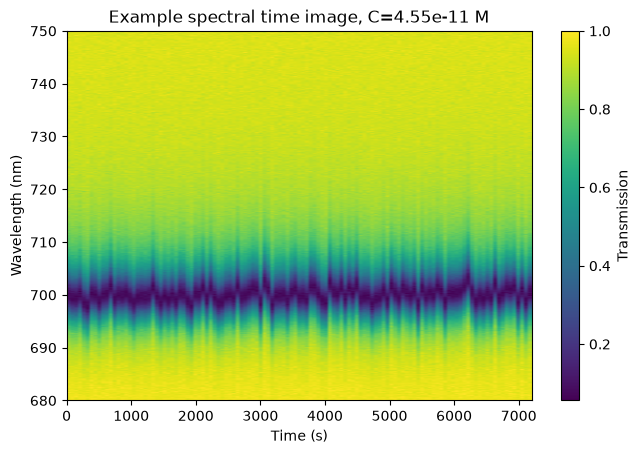

In [ ]:
example = np.asarray(images[0], dtype=np.float32)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
im = ax.imshow(example, aspect='auto', origin='lower', extent=[times_s.min(), times_s.max(), wavelength_nm.min(), wavelength_nm.max()], cmap='viridis')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Wavelength (nm)')
ax.set_title(f"Example spectral time image, C={metadata.loc[0, 'concentrationM']:.3g} M")
fig.colorbar(im, ax=ax, label='Transmission')
fig.savefig(out_dir / 'example_spectral_time_image.svg')

plt.close(fig)
print(f'Wrote {image_path}')
print(f'Wrote {metadata_path}')
